# Assignment 4 - K-Means Clustering on Iris Dataset

Perform clustering analysis using K-Means and determine the number of clusters with the elbow method.

*Dataset: `prac1/Iris.csv`.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

## 1. Load and prepare the data

In [2]:
df = pd.read_csv("./Iris.csv")
df = df.drop(columns=["Id"], errors="ignore")

X = df.drop(columns=["Species"])
y = df["Species"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Dataset shape:", X.shape)
print("Missing values:", X.isna().sum().sum())
print("Classes:", y.unique())

Dataset shape: (150, 4)
Missing values: 0
Classes: <StringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str


## 2. Elbow method

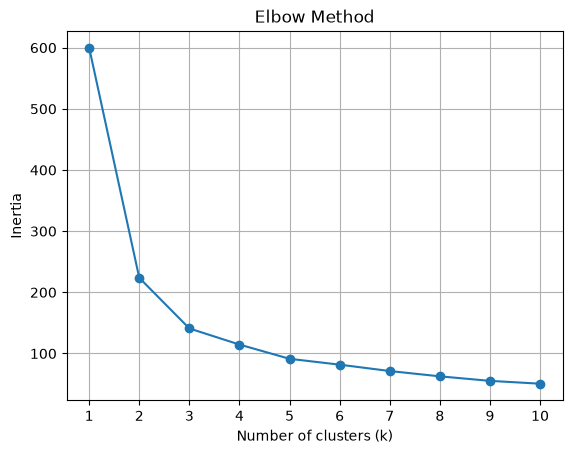

In [3]:
inertia = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.plot(k_values, inertia, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

## 3. Build the K-Means model

In [4]:
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

print("Cluster sizes:", np.bincount(clusters))
print("Silhouette score:", round(silhouette_score(X_scaled, clusters), 4))
print("Adjusted Rand index:", round(adjusted_rand_score(y, clusters), 4))

Cluster sizes: [53 50 47]
Silhouette score: 0.459
Adjusted Rand index: 0.6201


## 4. Visualize the clusters

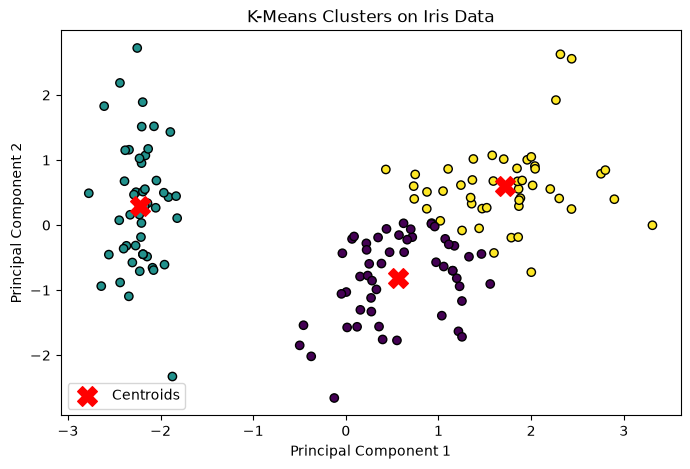

In [5]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap="viridis", edgecolor="k")
plt.scatter(
    pca.transform(kmeans.cluster_centers_)[:, 0],
    pca.transform(kmeans.cluster_centers_)[:, 1],
    marker="X",
    s=200,
    c="red",
    label="Centroids",
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters on Iris Data")
plt.legend()
plt.show()

## Conclusion

The elbow in the inertia curve occurs around k = 3, so three clusters are selected. K-Means groups the Iris samples into three clusters that correspond reasonably well to the three species.